# 实验六 A · 六色版画风格迁移
使用简化的 [pix2pix](https://phillipi.github.io/pix2pix/) 条件 GAN，从照片学习生成六色版画。配对目标由固定规则制作。保持模型初值、批次顺序和训练时长一致，只改变 L1 重构权重。

In [1]:
from pathlib import Path
import sys, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.transforms.functional import to_tensor
from torch.utils.data import TensorDataset, DataLoader
from skimage.metrics import structural_similarity
root = Path('exp6' if Path('exp6/data_index.csv').exists() else '.').resolve()
sys.path.insert(0, str(root))
from style_data import photo, poster, PALETTE
out = root/'results'/'exp6A'; out.mkdir(parents=True, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
seed = 6026
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('设备', device)

设备 cuda


## 数据与配对目标
使用仓库 COCO-CN 子集的训练和测试划分。清单保存原图 URL、描述与 SHA-256。先中心裁剪为 96×96，再对同一视野中值滤波，并按灰度分段映射到六种颜色。模型输入和目标均归一化到 [−1, 1]。

In [2]:
index = pd.read_csv(root/'data_index.csv')
def load_pairs(split):
    xs, ys = [], []
    for row in index[index.split == split].itertuples():
        image = photo(row, root, 96)
        xs.append(to_tensor(image)*2-1)
        ys.append(to_tensor(poster(image))*2-1)
    return torch.stack(xs), torch.stack(ys)
train_x, train_y = load_pairs('train'); test_x, test_y = load_pairs('test')
print('训练 / 测试', len(train_x), len(test_x))

训练 / 测试 256 40


## 生成器与条件判别器
生成器用三层下采样、跳跃连接和上采样恢复空间布局。判别器在通道方向拼接原图和候选风格图，并对局部图块输出真假分数。

In [3]:
def down(a,b):
    return nn.Sequential(nn.Conv2d(a,b,4,2,1),nn.GroupNorm(4,b),nn.LeakyReLU(0.2))
def up(a,b):
    return nn.Sequential(nn.Upsample(scale_factor=2,mode='nearest'),nn.Conv2d(a,b,3,padding=1),nn.GroupNorm(4,b),nn.ReLU())
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.d1, self.d2, self.d3 = down(3,24), down(24,48), down(48,96)
        self.u2, self.u1 = up(96,48), up(96,24)
        self.head = nn.Sequential(up(48,24),nn.Conv2d(24,3,3,padding=1),nn.Tanh())
    def forward(self,x):
        a = self.d1(x); b = self.d2(a)
        c = self.u2(self.d3(b)); d = self.u1(torch.cat([b,c],1))
        return self.head(torch.cat([a,d],1))
def discriminator():
    return nn.Sequential(down(6,24),down(24,48),down(48,96),nn.Conv2d(96,1,3,padding=1))

## 对照训练
两组均使用 Adam、学习率 0.0003、batch size 16，共训练 15 轮。生成器目标为对抗 BCE 加 λ 倍 L1。分别记录未加权损失，在第 1、5、15 轮保存同一测试照片的输出。

In [4]:
def rgb(t):
    return ((t.detach().cpu().permute(1,2,0).numpy()+1)/2).clip(0,1)
weights = [1, 50]; epochs = 15
history, evolution, predictions = [], {}, {}
bce = nn.BCEWithLogitsLoss()
for weight in weights:
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    loader = DataLoader(TensorDataset(train_x,train_y), batch_size=16, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    g, d = Generator().to(device), discriminator().to(device)
    opt_g, opt_d = [torch.optim.Adam(m.parameters(),lr=3e-4,betas=(0.5,0.999)) for m in (g,d)]
    for epoch in range(1,epochs+1):
        sums = np.zeros(3)
        for x,y in loader:
            x,y = x.to(device),y.to(device); fake = g(x)
            real_scores = d(torch.cat([x,y],1)); fake_scores = d(torch.cat([x,fake.detach()],1))
            loss_d = (bce(real_scores,torch.ones_like(real_scores))+bce(fake_scores,torch.zeros_like(fake_scores)))/2
            opt_d.zero_grad(); loss_d.backward(); opt_d.step()
            d.requires_grad_(False)
            scores = d(torch.cat([x,fake],1)); adv = bce(scores,torch.ones_like(scores)); l1 = (fake-y).abs().mean()
            opt_g.zero_grad(); (adv+weight*l1).backward(); opt_g.step(); d.requires_grad_(True)
            sums += [adv.item(),l1.item(),loss_d.item()]
        history.append([weight,epoch,*(sums/len(loader))])
        if epoch in [1,5,epochs]:
            with torch.no_grad(): evolution[weight,epoch] = rgb(g(test_x[:1].to(device))[0])
    with torch.no_grad(): predictions[weight] = torch.cat([g(x.to(device)).cpu() for x in test_x.split(8)])
hist = pd.DataFrame(history,columns=['lambda_l1','epoch','adversarial','l1','discriminator'])
hist.to_csv(out/'loss.csv',index=False)

## 测试集指标和图像
MAE 与 SSIM 对照配对目标，评价像素偏差和结构相似性。调色板距离为每个生成像素到最近目标色的 RGB 欧氏距离均值，按 [0,1] 计。该距离单独使用时无法反映图像内容。

,MAE,SSIM,palette_distance
lambda_l1,,,
1,0.075697,0.559247,0.120095
50,0.056031,0.687979,0.083424


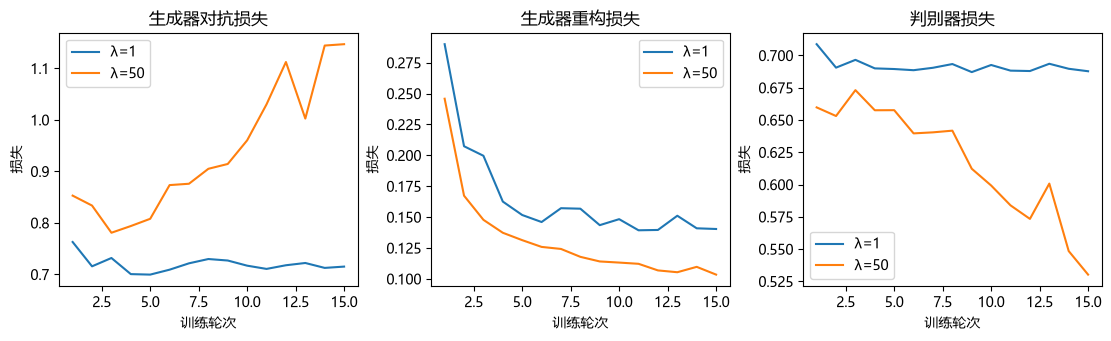

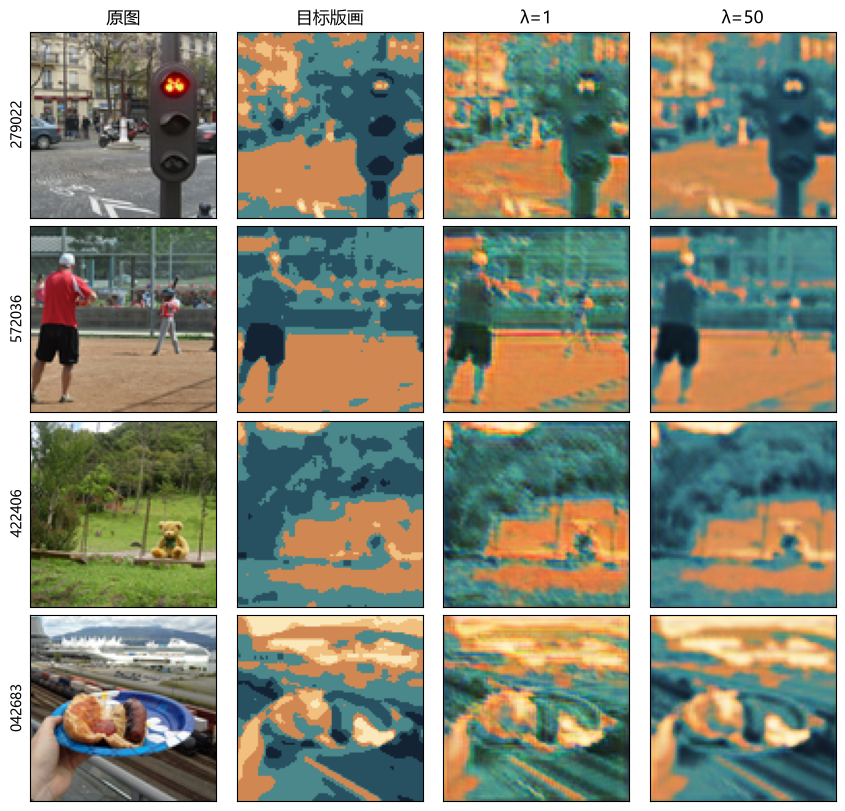

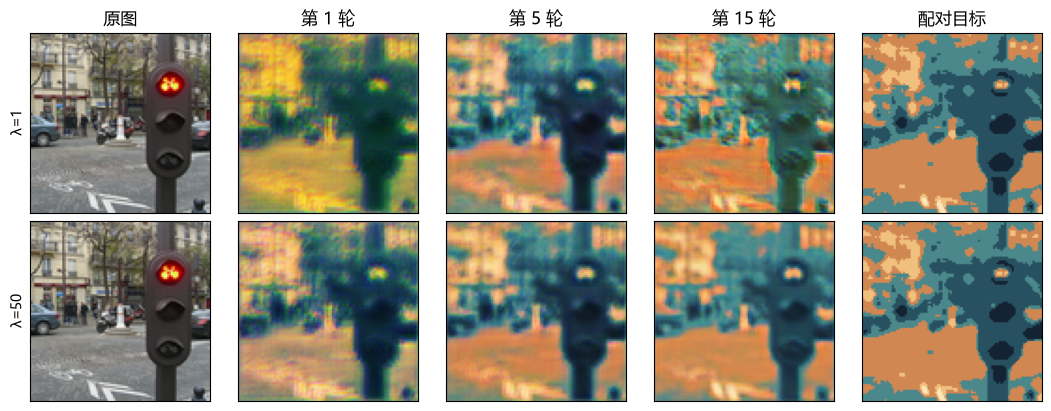

In [5]:
rows = []; ids = index.loc[index.split=='test','image_id'].tolist()
for weight in weights:
    for image_id,p,t in zip(ids,predictions[weight],test_y):
        a,b = rgb(p),rgb(t)
        distance = np.linalg.norm(a[:,:,None,:]-PALETTE/255,axis=-1).min(axis=-1).mean()
        rows.append([image_id,weight,np.abs(a-b).mean(),structural_similarity(a,b,data_range=1,channel_axis=2),distance])
scores = pd.DataFrame(rows,columns=['image_id','lambda_l1','MAE','SSIM','palette_distance'])
scores.to_csv(out/'per_image.csv',index=False)
summary = scores.groupby('lambda_l1').mean(numeric_only=True)
summary.to_csv(out/'metrics.csv'); display(summary)
fig,axes = plt.subplots(1,3,figsize=(11,3.3),layout='constrained')
for ax,col,title in zip(axes,['adversarial','l1','discriminator'],['生成器对抗损失','生成器重构损失','判别器损失']):
    for weight,h in hist.groupby('lambda_l1'): ax.plot(h.epoch,h[col],label=f'λ={weight}')
    ax.set(title=title,xlabel='训练轮次',ylabel='损失'); ax.legend()
fig.savefig(out/'loss.png',dpi=160); plt.show()
def grid(rows, titles, labels, path):
    fig,axes = plt.subplots(len(rows),len(titles),figsize=(2.1*len(titles),2*len(rows)),layout='constrained')
    for i,row in enumerate(rows):
        for j,img in enumerate(row):
            ax = axes[i,j]; ax.imshow(img); ax.set(xticks=[],yticks=[])
            if i==0: ax.set_title(titles[j])
            if j==0: ax.set_ylabel(labels[i])
    fig.savefig(out/path,dpi=150); plt.show()
grid([[rgb(test_x[i]),rgb(test_y[i]),*[rgb(predictions[w][i]) for w in weights]] for i in range(4)],
     ['原图','目标版画','λ=1','λ=50'],[s[-6:] for s in ids[:4]],'comparison.png')
grid([[rgb(test_x[0]),*[evolution[w,e] for e in [1,5,15]],rgb(test_y[0])] for w in weights],
     ['原图','第 1 轮','第 5 轮','第 15 轮','配对目标'],[f'λ={w}' for w in weights],'evolution.png')